Streaming output truncated to the last 5000 lines.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading packa

Classifier: Multinomial Naive Bayes
F1 Score: 0.7248620518046601
Recall: 0.7701112103255134
Accuracy: 0.7701112103255134
Precision: 0.6882399776747571
Confusion Matrix:
[[4355  554    0]
 [ 866 5132    0]
 [ 978  434    0]]



/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


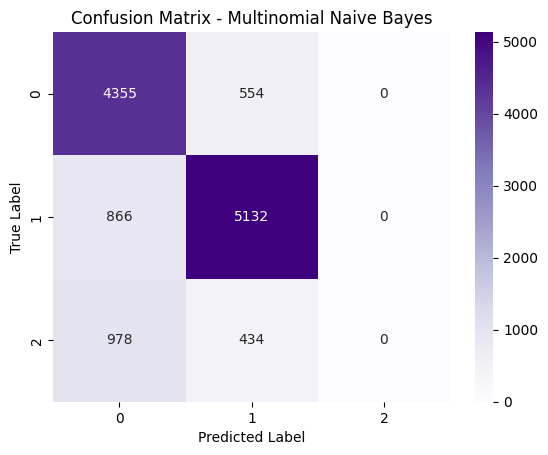

Classifier: Logistic Regression
F1 Score: 0.7510579995615859
Recall: 0.7875639256433152
Accuracy: 0.7875639256433152
Precision: 0.744195995340668
Confusion Matrix:
[[4383  459   67]
 [ 674 5257   67]
 [ 879  471   62]]



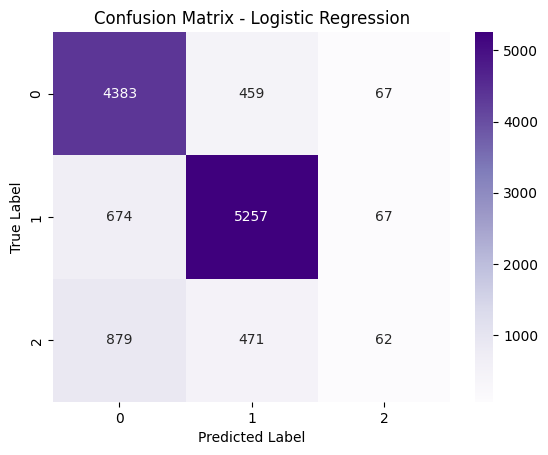

Classifier: Support Vector Machine
F1 Score: 0.7458361707780182
Recall: 0.7901615390859648
Accuracy: 0.7901615390859648
Precision: 0.7511735038717516
Confusion Matrix:
[[4484  415   10]
 [ 750 5237   11]
 [ 971  428   13]]



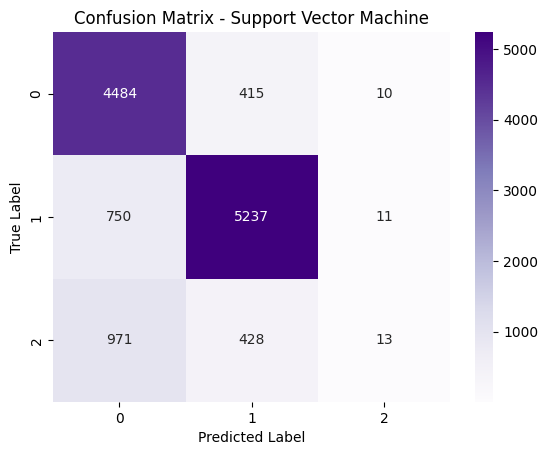

Classifier: Random Forest
F1 Score: 0.72818373209659
Recall: 0.7723841220878318
Accuracy: 0.7723841220878318
Precision: 0.712503189996328
Confusion Matrix:
[[4418  482    9]
 [ 898 5094    6]
 [1010  399    3]]



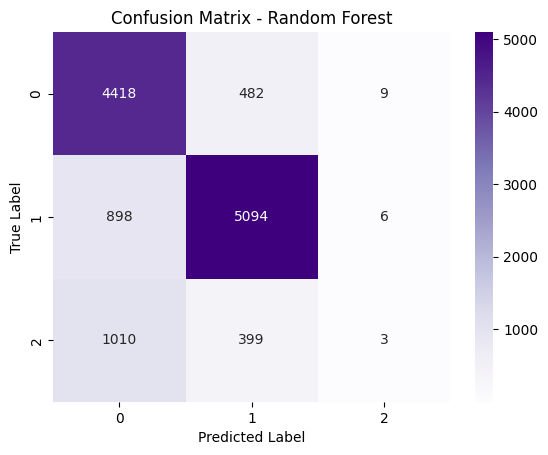

Classifier: K-Nearest Neighbors
F1 Score: 0.6647920671280657
Recall: 0.7023297345563764
Accuracy: 0.7023297345563764
Precision: 0.6512732268005499
Confusion Matrix:
[[3421 1397   91]
 [ 767 5196   35]
 [ 766  611   35]]



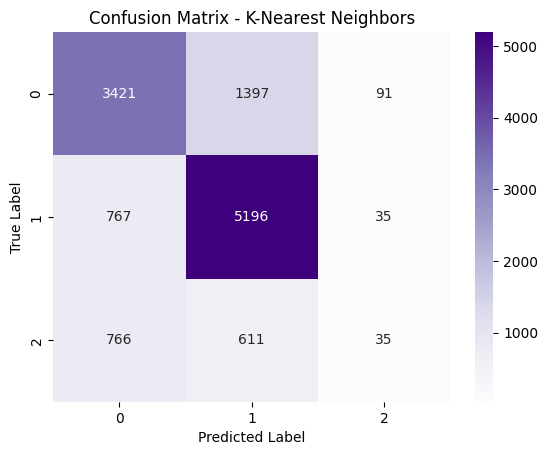

Classifier: Gradient Boosting
F1 Score: 0.6998720627494367
Recall: 0.7409692345157887
Accuracy: 0.7409692345157887
Precision: 0.7126862613947956
Confusion Matrix:
[[4255  642   12]
 [1131 4858    9]
 [ 933  464   15]]



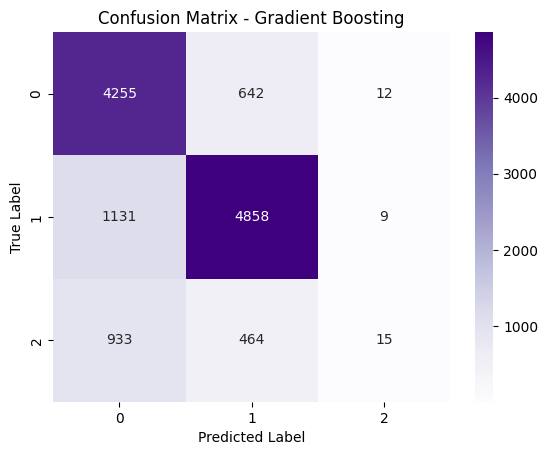

Classifier: Artificial Neural Network
F1 Score: 0.7310173748066696
Recall: 0.7410504099358715
Accuracy: 0.7410504099358715
Precision: 0.723498077760968
Confusion Matrix:
[[3885  582  442]
 [ 687 5010  301]
 [ 746  432  234]]



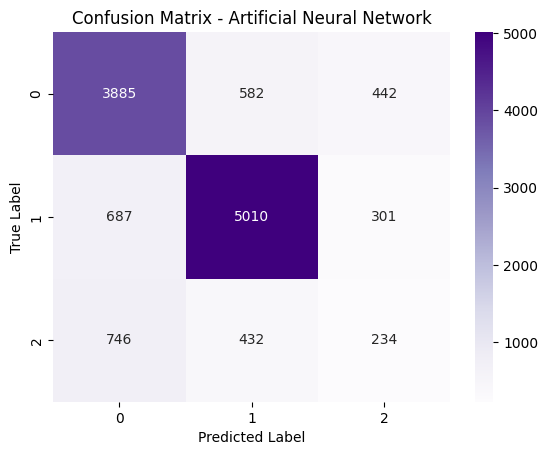

Best Classifier based on Accuracy: Support Vector Machine


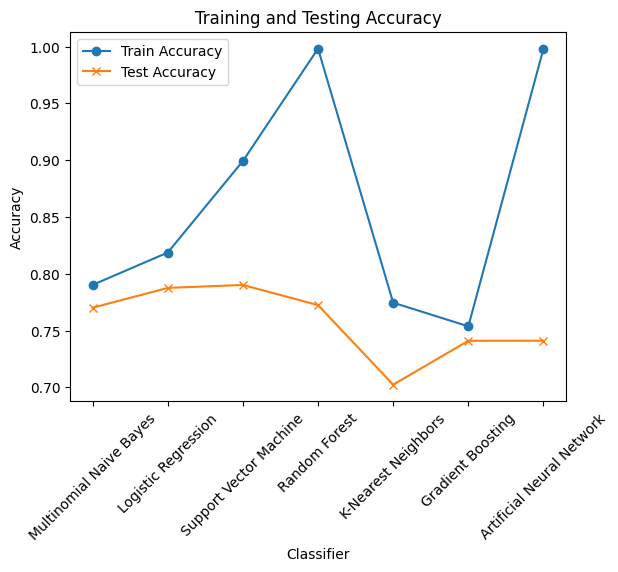

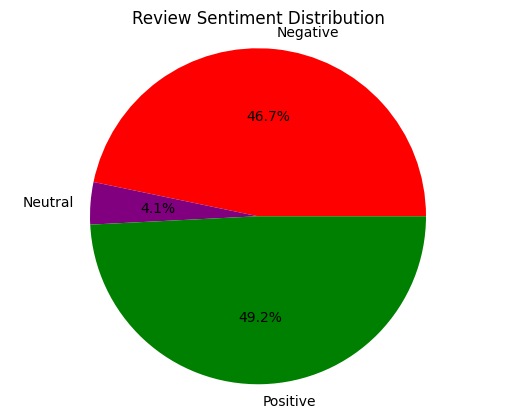

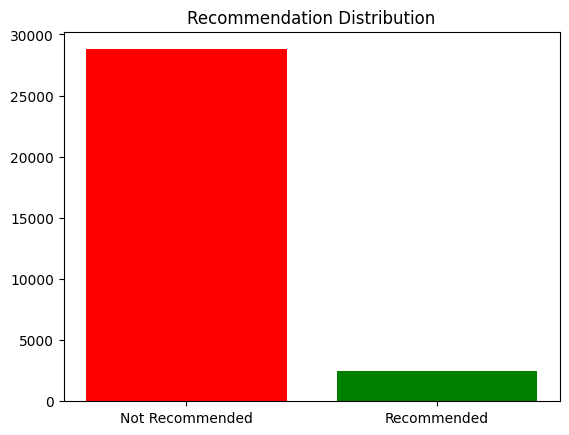

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from collections import Counter
import seaborn as sns
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Load the dataset
data = pd.read_csv('/content/sample_data/spotifyappreviews.csv')

# Preprocess the 'Review' column
def preprocess(text):
    # Lowercasing
    text = text.lower()

    # Tokenization
    #nltk.download('punkt')
    words = word_tokenize(text)

    # Removing stopwords
    #nltk.download('stopwords')
    stop_words = set(stopwords.words('english'))
    words = [word for word in words if word not in stop_words]

    # Join the words back to form the preprocessed text
    preprocessed_text = " ".join(words)
    return preprocessed_text

data['Review'] = data['Review'].apply(preprocess)

# Split the data into features (X) and target (y)
X = data['Review']
y = data['Rating'].apply(lambda x: 1 if x > 3 else (0 if x < 3 else 2))  # Positive: 1, Negative: 0, Neutral: 2

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Text vectorization
vectorizer = TfidfVectorizer()  # You can also use CountVectorizer if you prefer
X_train_vectorized = vectorizer.fit_transform(X_train)
X_test_vectorized = vectorizer.transform(X_test)

# Define classifiers
classifiers = [
    ('Multinomial Naive Bayes', MultinomialNB()),
    ('Logistic Regression', LogisticRegression(max_iter=500)),
    ('Support Vector Machine', SVC()),
    ('Random Forest', RandomForestClassifier()),
    ('K-Nearest Neighbors', KNeighborsClassifier()),
    ('Gradient Boosting', GradientBoostingClassifier()),
    ('Artificial Neural Network', MLPClassifier(max_iter=500))
]

# Train and evaluate classifiers
train_accuracy = []
test_accuracy = []
best_accuracy = 0
best_classifier_name = None
best_classifier = None

for name, clf in classifiers:
    clf.fit(X_train_vectorized, y_train)
    y_pred_train = clf.predict(X_train_vectorized)
    y_pred_test = clf.predict(X_test_vectorized)

    train_accuracy.append(accuracy_score(y_train, y_pred_train))
    test_accuracy.append(accuracy_score(y_test, y_pred_test))

    print(f"Classifier: {name}")
    print(f"F1 Score: {f1_score(y_test, y_pred_test, average='weighted')}")
    print(f"Recall: {recall_score(y_test, y_pred_test, average='weighted')}")
    print(f"Accuracy: {accuracy_score(y_test, y_pred_test)}")
    print(f"Precision: {precision_score(y_test, y_pred_test, average='weighted')}")
    cm = confusion_matrix(y_test, y_pred_test)
    print(f"Confusion Matrix:\n{cm}\n")

    # Plot confusion matrix with numbers using seaborn heatmap
    plt.figure()
    ax = plt.subplot()
    sns.heatmap(cm, annot=True, fmt="d", cmap=plt.cm.Purples, ax=ax)
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    ax.set_title(f'Confusion Matrix - {name}')
    plt.show()

    if accuracy_score(y_test, y_pred_test) > best_accuracy:
        best_accuracy = accuracy_score(y_test, y_pred_test)
        best_classifier_name = name
        best_classifier = clf

# Print the best classifier
print(f"Best Classifier based on Accuracy: {best_classifier_name}")

# Training and testing spline graph
plt.plot(range(len(train_accuracy)), train_accuracy, label='Train Accuracy', marker='o')
plt.plot(range(len(test_accuracy)), test_accuracy, label='Test Accuracy', marker='x')
plt.xlabel('Classifier')
plt.ylabel('Accuracy')
plt.title('Training and Testing Accuracy')
plt.xticks(range(len(train_accuracy)), [name for name, _ in classifiers], rotation=45)
plt.legend()
plt.show()

# Apply the best classifier on the whole dataset
best_classifier.fit(vectorizer.transform(X), y)
data['predicted_label'] = best_classifier.predict(vectorizer.transform(X))

# Draw pie chart and bar graph for positive, negative, neutral reviews
review_sentiment_counts = Counter(data['predicted_label'])

labels = ['Negative', 'Neutral', 'Positive']
colors = ['red', 'purple', 'green']
sizes = [review_sentiment_counts[0], review_sentiment_counts[2], review_sentiment_counts[1]]

plt.pie(sizes, labels=labels, colors=colors, autopct='%1.1f%%')
plt.title('Review Sentiment Distribution')
plt.axis('equal')
plt.show()

recommendation_labels = ['Not Recommended', 'Recommended']
recommendation_colors = ['red', 'green']
recommendation_sizes = [review_sentiment_counts[0], review_sentiment_counts[2]]

plt.bar(recommendation_labels, recommendation_sizes, color=recommendation_colors)
plt.title('Recommendation Distribution')
plt.show()

